In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\ak038\OneDrive\Desktop\Casmpus X\data\FIFA_World_Cup_Champions_1930_2022.csv")

In [4]:
df.head()

,year,host_country,host_city_final,stadium,winner,runner_up,winner_captain,winner_head_coach,win_method,winner_goals,...,matches_played,winner_titles_after_win,continent_winner,golden_ball,golden_boot,best_young_player,golden_glove,top_scorer_goals,mascot,official_ball
0,1930,Uruguay,Montevideo,Estadio Centenario,Uruguay,Argentina,José Nasazzi,Alberto Suppici,Regular Time,4,...,18,1,South America,NaN,Guillermo Stábile,NaN,NaN,8,NaN,T-Model
1,1934,Italy,Rome,Stadio Nazionale PNF,Italy,Czechoslovakia,Gianpiero Combi,Vittorio Pozzo,Extra Time,2,...,17,1,Europe,NaN,Oldřich Nejedlý,NaN,NaN,5,NaN,Federale 102
2,1938,France,Paris,Stade Olympique de Colombes,Italy,Hungary,Giuseppe Meazza,Vittorio Pozzo,Regular Time,4,...,18,2,Europe,NaN,Leônidas,NaN,NaN,7,NaN,Allen
3,1950,Brazil,Rio de Janeiro,Maracanã,Uruguay,Brazil,Obdulio Varela,Juan López Fontana,Regular Time,2,...,22,2,South America,NaN,Ademir,NaN,NaN,9,NaN,Super Duplo T
4,1954,Switzerland,Bern,Wankdorf Stadium,West Germany,Hungary,Fritz Walter,Sepp Herberger,Regular Time,3,...,26,1,Europe,NaN,Sándor Kocsis,NaN,NaN,11,NaN,Swiss World Champion


In [5]:
numeric_cols=df.select_dtypes(include="number")
numeric_cols

,year,winner_goals,runner_up_goals,attendance,total_teams,matches_played,winner_titles_after_win,top_scorer_goals
0,1930,4,2,68346,13,18,1,8
1,1934,2,1,55000,16,17,1,5
2,1938,4,2,45000,15,18,2,7
3,1950,2,1,173850,13,22,2,9
4,1954,3,2,62500,16,26,1,11
5,1958,5,2,49737,16,35,1,13
6,1962,3,1,68679,16,32,2,4
7,1966,4,2,96924,16,32,1,9
8,1970,4,1,107412,16,32,3,10
9,1974,2,1,78200,16,38,2,7


In [ ]:
cat_cols=df.select_dtypes(include=["string","object","category"])
cat_cols

<Axes: xlabel='attendance', ylabel='matches_played'>

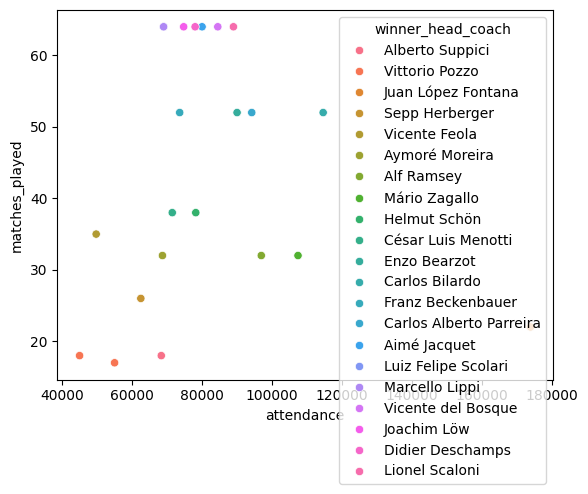

In [9]:
sns.scatterplot(x=df["attendance"],y=df["matches_played"],hue=df["winner_head_coach"])

In [17]:
numeric_cols.columns.tolist()

['year',
 'winner_goals',
 'runner_up_goals',
 'attendance',
 'total_teams',
 'matches_played',
 'winner_titles_after_win',
 'top_scorer_goals']

In [18]:
cat_cols.columns.tolist()

['host_country',
 'host_city_final',
 'stadium',
 'winner',
 'runner_up',
 'winner_captain',
 'winner_head_coach',
 'win_method',
 'continent_winner',
 'golden_ball',
 'golden_boot',
 'best_young_player',
 'golden_glove',
 'mascot',
 'official_ball']

<Axes: xlabel='winner', ylabel='year'>

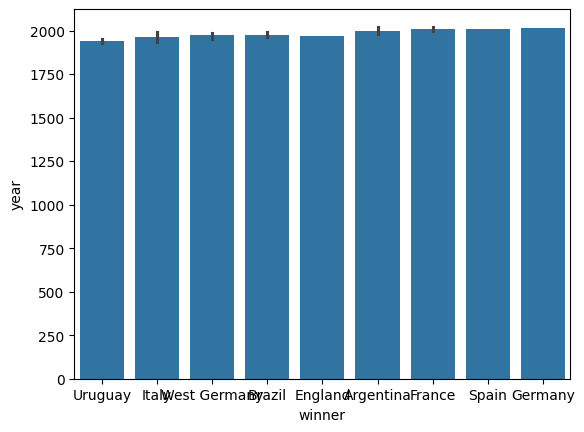

In [23]:
sns.barplot(x=df["winner"],y=df["year"])

<Axes: xlabel='winner', ylabel='matches_played'>

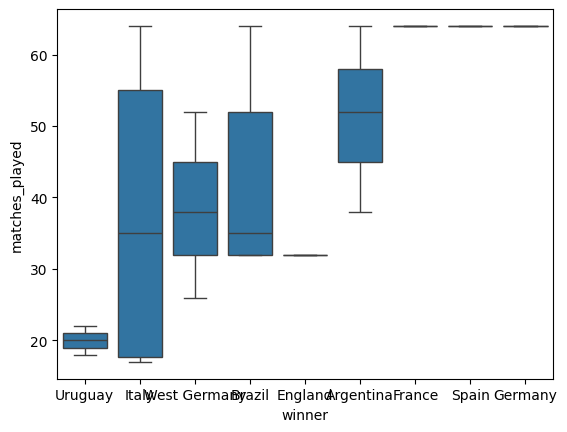

In [29]:
sns.boxplot(x=df["winner"],y=df["matches_played"])

<Axes: xlabel='winner_goals', ylabel='Count'>

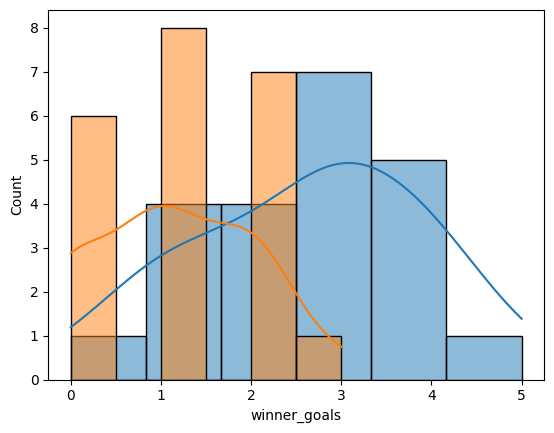

In [38]:
sns.histplot(x=df["winner_goals"],kde=True,)
sns.histplot(x=df["runner_up_goals"],kde=True)

<Axes: xlabel='winner_goals', ylabel='Density'>

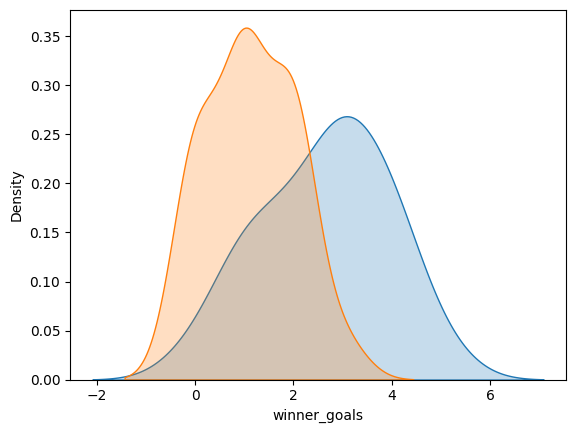

In [42]:
sns.kdeplot(df["winner_goals"],fill=True)
sns.kdeplot(df["runner_up_goals"],fill=True)

In [44]:
sns.heatmap(df["continent_winner",df["host_country"]])

InvalidIndexError: ('continent_winner', 0               Uruguay
1                 Italy
2                France
3                Brazil
4           Switzerland
5                Sweden
6                 Chile
7               England
8                Mexico
9          West Germany
10            Argentina
11                Spain
12               Mexico
13                Italy
14        United States
15               France
16    South Korea/Japan
17              Germany
18         South Africa
19               Brazil
20               Russia
21                Qatar
Name: host_country, dtype: str)

In [47]:
pivot_table=pd.crosstab(df["continent_winner"],df["winner"])
pivot_table

winner,Argentina,Brazil,England,France,Germany,Italy,Spain,Uruguay,West Germany
continent_winner,,,,,,,,,
Europe,0,0,1,2,1,4,1,0,3
South America,3,5,0,0,0,0,0,2,0


<Axes: xlabel='winner', ylabel='continent_winner'>

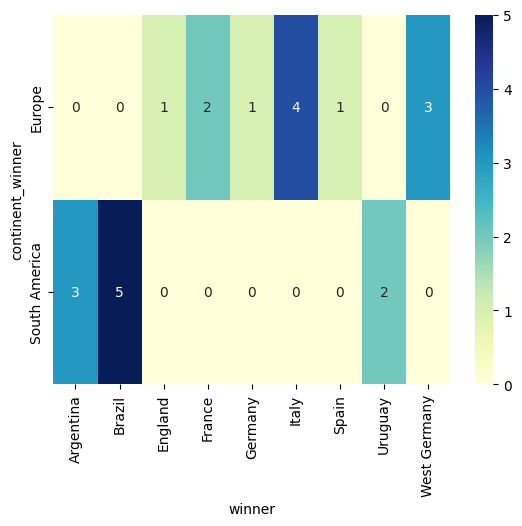

In [46]:
sns.heatmap(pivot_table, annot=True, cmap="YlGnBu", fmt="d")

<Axes: xlabel='winner', ylabel='win_method'>

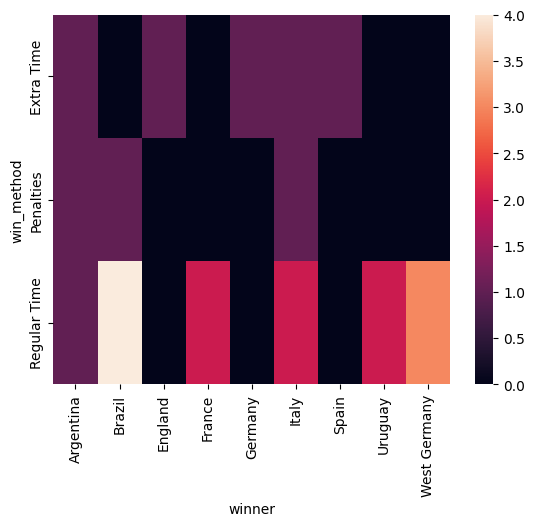

In [51]:
sns.heatmap(pd.crosstab(df["win_method"],df["winner"]))

In [55]:
numeric_cols

,year,winner_goals,runner_up_goals,attendance,total_teams,matches_played,winner_titles_after_win,top_scorer_goals
0,1930,4,2,68346,13,18,1,8
1,1934,2,1,55000,16,17,1,5
2,1938,4,2,45000,15,18,2,7
3,1950,2,1,173850,13,22,2,9
4,1954,3,2,62500,16,26,1,11
5,1958,5,2,49737,16,35,1,13
6,1962,3,1,68679,16,32,2,4
7,1966,4,2,96924,16,32,1,9
8,1970,4,1,107412,16,32,3,10
9,1974,2,1,78200,16,38,2,7


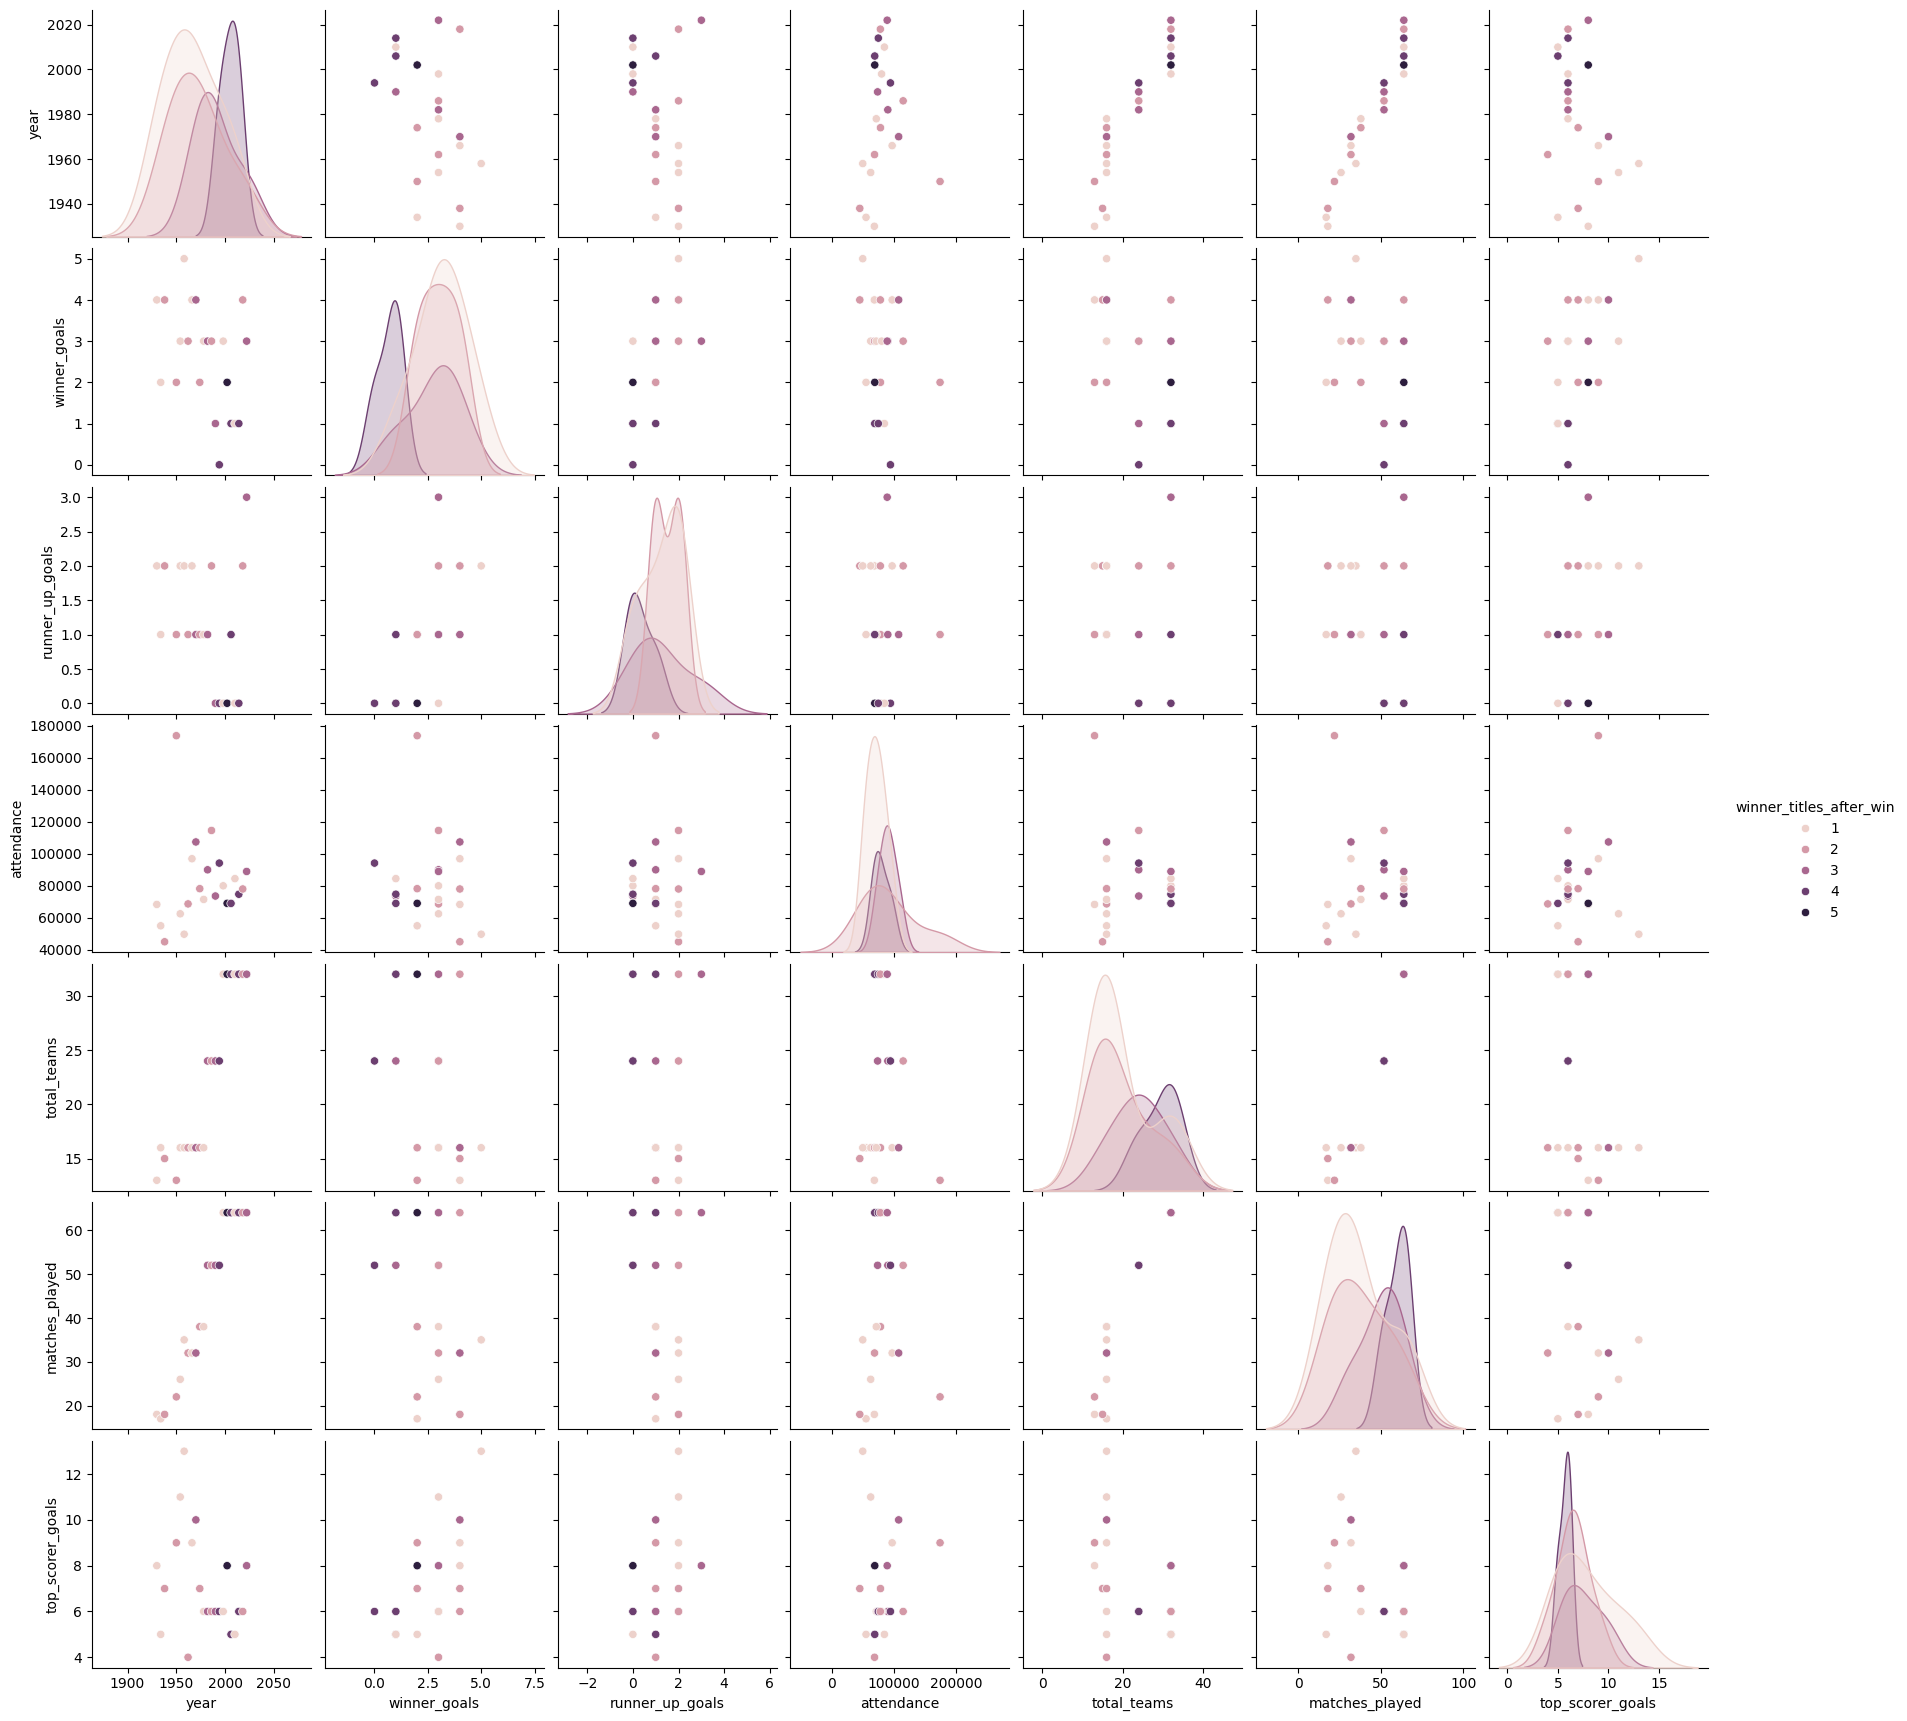

In [60]:
sns.pairplot(numeric_cols,hue="winner_titles_after_win")

<Axes: xlabel='year', ylabel='winner_goals'>

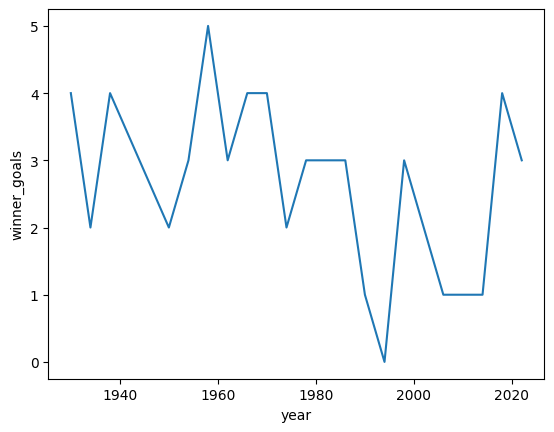

In [61]:
sns.lineplot(x=df["year"],y=df["winner_goals"])

<Axes: xlabel='winner_titles_after_win', ylabel='total_teams'>

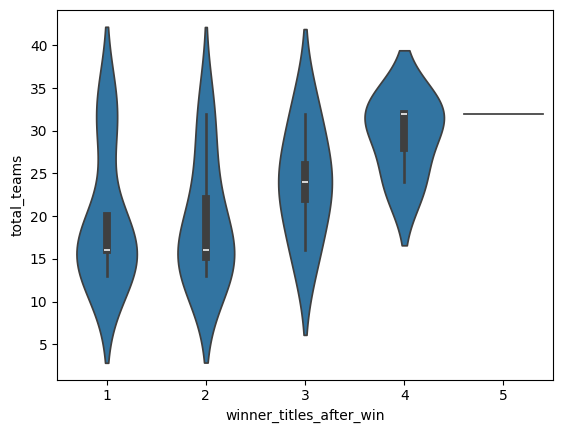

In [62]:
# Compare a numeric column across categories
sns.violinplot(data=df, x="winner_titles_after_win", y="total_teams")

